**Logistic Regression + T0: no additional feature transformation**

This training involves the following steps: 
1. Load the shared splits
2. Build a sklearn pipeline
3. Train six regularization settings
4. Plot the validation curve
5. Select by validation F1
6. Inspect errors and save six comparable results rows

T0 is the **73-feature preprocessed baseline**. It still uses the shared category grouping, one-hot encoding, log1p and scaling. 
These are 6 of the project's minimum 72 model configurations. The official test set is neither loaded nor scored in this notebook.

**Logistic regression: probability, loss and regularization**
**Logistic regression** predicts the probability of an attack as $P(\text{attack}) = \sigma(w^\top x + b)$, where $\sigma(z) = 1 / (1 + e^{-z})$ squashes any number into (0, 1). It flags a flow as an attack when that probability is above 0.5, so the decision boundary $w^\top x + b = 0$ is a straight line (hyperplane) in the feature space it sees.

**Regularization:** sklearn minimizes

$$\frac{1}{2}\lVert w \rVert^2 + C \sum_{i} \text{log-loss}_i$$

`C` sets how much the model cares about fitting the training data compared to keeping the weights small.

**Smaller C means stronger regularization** and more weight shrinkage; **larger C
means weaker regularization**. Changing C adjusts the fitted coefficients, not
the number of input features or the form of the T0 decision boundary.

Sources: [sklearn logistic-regression formulation](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)
and [LogisticRegression parameters](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

**1. Setup and shared splits**

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "preprocessing.py").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.linear_model import LogisticRegression

from src.preprocessing import RANDOM_STATE, NOT_FEATURES, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

required_splits = [ROOT / "data" / "processed" / f"{name}.csv" for name in ("train", "val")]
if not all(path.is_file() for path in required_splits):
    raise FileNotFoundError(
        "Run notebook/preprocessing.ipynb first to create data/processed/train.csv and val.csv."
    )
X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")

assert X_train.shape == (24_000, 41)
assert X_val.shape == (6_000, 41)
assert X_train.columns.equals(X_val.columns)
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert not set(NOT_FEATURES).intersection(X_train.columns)
train_ids = pd.read_csv(required_splits[0], usecols=["id"])["id"]
val_ids = pd.read_csv(required_splits[1], usecols=["id"])["id"]
assert set(train_ids).isdisjoint(val_ids)
print("Raw inputs — train:", X_train.shape, "validation:", X_val.shape)
print("Train/validation row-ID overlap: 0. Test split not loaded.")

Raw inputs — train: (24000, 41) validation: (6000, 41)
Train/validation row-ID overlap: 0. Test split not loaded.


In [2]:
class_balance = pd.DataFrame({
    "train_count": y_train.value_counts().reindex([0, 1], fill_value=0),
    "val_count": y_val.value_counts().reindex([0, 1], fill_value=0),
}).rename(index={0: "Normal", 1: "Attack"})
class_balance["train_share"] = class_balance["train_count"] / len(y_train)
class_balance["val_share"] = class_balance["val_count"] / len(y_val)
display(class_balance.round(4))

,train_count,val_count,train_share,val_share
label,,,,
Normal,11559,2890,0.4816,0.4817
Attack,12441,3110,0.5184,0.5183


**2. T0 representation and what the dataset implies**

For T0, $\phi_0(u)=u$: use all shared preprocessed columns directly. T2 instead
uses PCA scores; here no principal components or variance directions are dropped.

| Dataset finding | Effect on this baseline |
|---|---|
| Heavy-tailed byte, packet and timing features | Shared log1p reduces extreme ranges; scaling prevents units alone from determining the L2 penalty. |
| Three categorical features | One-hot indicators give the model additive category-specific log-odds contributions. Service `-` remains a legitimate category. |
| Correlated numeric features | T0 retains their information and redundancy. L2 shrinks coefficients, but correlated features can share weights, making individual coefficients unstable. |
| About 51.8% attacks after deduplication | Use the same unweighted fit as T2 (`class_weight=None`), and report attack precision/recall/F1 and normal-traffic FPR. This prevalence does not establish deployment precision. |
| Conflicting feature vectors with different labels | Identical inputs cannot receive different deterministic predictions; perfect separation is not guaranteed even with weak regularization. |
| Strong TTL associations in the lab data | T0 retains `sttl`, `dttl` and `ct_state_ttl`. High scores may partly reflect the lab setup; this run alone does not establish transfer to real traffic. |
| No additional basis functions | The model cannot directly learn feature products, category-by-numeric interactions or local curved boundaries. A small train/validation gap alone does not prove underfitting. |

Training has 24,000 rows and validation has 6,000. The shared notebook stratifies
on `attack_cat`, preserving rare attack types as well as binary balance. Its fixed
EDA feature/category lists are reused for direct comparison with T2; fitted
scaler statistics come only from the training rows. This is a fitting holdout,
not data that was entirely unseen during the earlier full-file EDA.

In [3]:
# Diagnostic preprocessor only; every fitted model below receives its own instance.
preview_prep = build_preprocessor().fit(X_train)
Xt_train = preview_prep.transform(X_train)
Xt_val = preview_prep.transform(X_val)
feature_names = preview_prep.get_feature_names_out()
assert Xt_train.shape == (24_000, 73)
assert Xt_val.shape == (6_000, 73)
assert np.isfinite(Xt_train).all() and np.isfinite(Xt_val).all()
print("T0 train:", Xt_train.shape, "validation:", Xt_val.shape)
print("Identity mapping after preprocessing: Z = Xt (73 features).")
display(pd.Series(feature_names).str.split("__").str[0].value_counts().rename("columns"))

T0 train: (24000, 73) validation: (6000, 73)
Identity mapping after preprocessing: Z = Xt (73 features).


cat    35
log    31
num     7
Name: columns, dtype: int64

**3. The pipeline**

The full pipeline is **shared preprocessing (73 features) → logistic regression**.
The sklearn estimator uses L2 regularization, the `lbfgs` solver, an intercept,
no class reweighting and the same 2,000-iteration limit as T2. The installed sklearn
default penalty is L2; no PCA or other extra feature mapper is inserted.

Each call to `evaluate` fits a fresh pipeline on training only. Validation is used
for scoring and C selection, never for fitting scalers or coefficients. If a model
does not converge, investigate its iteration count and increase the limit before
interpreting its result. Cross-validation, if added later, should receive the
raw inputs and this complete pipeline.

In [4]:
def build(C):
    return make_pipeline(
        build_preprocessor(),
        LogisticRegression(C=C, solver="lbfgs", max_iter=2000,
                           class_weight=None, random_state=RANDOM_STATE),
    )

**4. Regularization sweep: six values of C**

Use the same logarithmic grid as T2 to isolate the effect of the representation.
These choices are planned comparisons, not claims that an unobserved model has
already overfit. All six models use the same rows and default prediction threshold.

| C | Why include it? |
|---|---|
| 0.001 | Strong shrinkage: test whether a heavily constrained additive model is sufficient. |
| 0.01 | Relax shrinkage tenfold to see whether the strongest setting suppresses useful signals. |
| 0.1 | Intermediate setting: allow larger coefficients while retaining substantial regularization. |
| 1 | sklearn's conventional default C, providing a familiar reference. |
| 10 | Weak regularization: check whether fitting subtler signals improves validation or mainly training. |
| 100 | Weakest regularization in the grid: test whether gains plateau or the train/validation gap widens. |

`f1_gap = train_f1 - val_f1`. A large positive gap can suggest overfitting. Similar
scores on both splits require inspecting their absolute level and error patterns;
they do not by themselves identify bias, noise or a lack of useful features.

In [5]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted = [], {}

for value in GRID:
    pipe = build(value)
    rows.append(evaluate(pipe, "LR", "T0", "C", value, X_train, y_train, X_val, y_val))
    fitted[value] = pipe
    print(f"C={value:g}: train F1={rows[-1]['train_f1']:.4f}, "
          f"val F1={rows[-1]['val_f1']:.4f}, fit time={rows[-1]['fit_time_s']}s, "
          f"converged={rows[-1]['converged']}")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
assert len(results) == 6 and results["value"].nunique() == 6
assert results["converged"].all(), "Increase max_iter and rerun before selecting a model."
display(results.drop(columns=["model", "transformation", "param"]).round(4))

C=0.001: train F1=0.9051, val F1=0.9046, fit time=0.03s, converged=True
C=0.01: train F1=0.9106, val F1=0.9099, fit time=0.04s, converged=True


C=0.1: train F1=0.9143, val F1=0.9133, fit time=0.05s, converged=True


C=1: train F1=0.9157, val F1=0.9140, fit time=0.1s, converged=True


C=10: train F1=0.9169, val F1=0.9132, fit time=0.15s, converged=True


C=100: train F1=0.9178, val F1=0.9141, fit time=0.21s, converged=True


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8474,0.9714,0.9051,0.1883,0.8501,0.9666,0.9046,0.1834,0.03,True,0.0005
1,0.010,0.8666,0.9592,0.9106,0.1589,0.8680,0.9559,0.9099,0.1564,0.04,True,0.0007
2,0.100,0.8742,0.9582,0.9143,0.1485,0.8776,0.9521,0.9133,0.1429,0.05,True,0.0009
3,1.000,0.8805,0.9537,0.9157,0.1393,0.8819,0.9486,0.9140,0.1367,0.10,True,0.0016
4,10.000,0.8839,0.9525,0.9169,0.1346,0.8841,0.9444,0.9132,0.1332,0.15,True,0.0037
5,100.000,0.8840,0.9542,0.9178,0.1347,0.8831,0.9473,0.9141,0.1349,0.21,True,0.0037


**5. Validation curve and regularization diagnostics**

As in T2, the left plot compares training and validation F1, and the right plot
shows validation precision, recall and FPR. The metrics use attack as the positive
class. Iteration counts and coefficient norms help verify convergence and the
weight-shrinkage effect. The norm is descriptive, not a model-selection metric.

In [6]:
plot_sweep(results, "LR T0", FIGS / "curve_lr_t0.png")

regularization_diagnostics = pd.DataFrame([
    {"C": value,
     "iterations": int(fitted[value].named_steps["logisticregression"].n_iter_.max()),
     "coefficient_L2_norm": np.linalg.norm(fitted[value].named_steps["logisticregression"].coef_)}
    for value in GRID
])
display(regularization_diagnostics.round(4))

,C,iterations,coefficient_L2_norm
0,0.001,16,1.5512
1,0.010,30,3.3260
2,0.100,68,7.0574
3,1.000,163,12.9927
4,10.000,261,20.6963
5,100.000,350,37.4760


In [7]:
strongest, weakest = results.iloc[0], results.iloc[-1]
peak = results.loc[results["val_f1"].idxmax()]
default_c = results.loc[results["value"] == 1].iloc[0]
display(Markdown(
    f"**Observed sweep:** validation F1 changes from {strongest['val_f1']:.4f} "
    f"at C={strongest['value']:g} to {weakest['val_f1']:.4f} at "
    f"C={weakest['value']:g}; the highest observed value is {peak['val_f1']:.4f} "
    f"at C={peak['value']:g}. Train-minus-validation F1 ranges from "
    f"{results['f1_gap'].min():+.4f} to {results['f1_gap'].max():+.4f}. "
    f"The best F1 differs from C=1 by only {peak['val_f1'] - default_c['val_f1']:+.6f}. "
    f"From the strongest to weakest regularization, FPR changes from "
    f"{strongest['val_fpr']:.2%} to {weakest['val_fpr']:.2%}, while recall changes "
    f"from {strongest['val_recall']:.2%} to {weakest['val_recall']:.2%}. "
    "The near tie with C=1 should not be presented as a robust advantage for C=100. "
    "These are descriptive differences on one fixed split, not significance tests. "
    "If training improves while validation worsens, stronger regularization is a "
    "candidate response. If both plateau, changing C alone may not address the "
    "remaining errors; compare alternative feature spaces and inspect the error types."
))

**Observed sweep:** validation F1 changes from 0.9046 at C=0.001 to 0.9141 at C=100; the highest observed value is 0.9141 at C=100. Train-minus-validation F1 ranges from +0.0005 to +0.0037. The best F1 differs from C=1 by only +0.000035. From the strongest to weakest regularization, FPR changes from 18.34% to 13.49%, while recall changes from 96.66% to 94.73%. The near tie with C=1 should not be presented as a robust advantage for C=100. These are descriptive differences on one fixed split, not significance tests. If training improves while validation worsens, stronger regularization is a candidate response. If both plateau, changing C alone may not address the remaining errors; compare alternative feature spaces and inspect the error types.

**6. The best setting and validation errors**

Select the highest validation F1, matching the template. Exact ties use the first
row in the ascending grid, so the stronger-regularized tied setting wins. A best
setting on a grid edge suggests checking a wider range later; it does not prove
that a wider range will improve performance. Validation is now part of model
selection, so its selected score is not a final unbiased test estimate.

In [8]:
best = results.loc[results["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"Best C={best['value']:g}: val F1={best['val_f1']:.4f}, "
      f"precision={best['val_precision']:.4f}, recall={best['val_recall']:.4f}, "
      f"FPR={best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("Best C is at the grid edge: consider a wider grid in a follow-up experiment.")

Best C=100: val F1=0.9141, precision=0.8831, recall=0.9473, FPR=0.1349
Best C is at the grid edge: consider a wider grid in a follow-up experiment.


Rows of the confusion matrix are true labels and columns are predicted labels.
False positives are normal flows flagged as attacks; false negatives are missed
attacks. The shared evaluator reports

$$\mathrm{Precision}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2TP}{2TP+FP+FN},\quad
\mathrm{FPR}=\frac{FP}{FP+TN}.$$

False positive rate is conditional on **normal** traffic, so the expected false
alarm count is FPR times the number of normal flows, not automatically all flows.

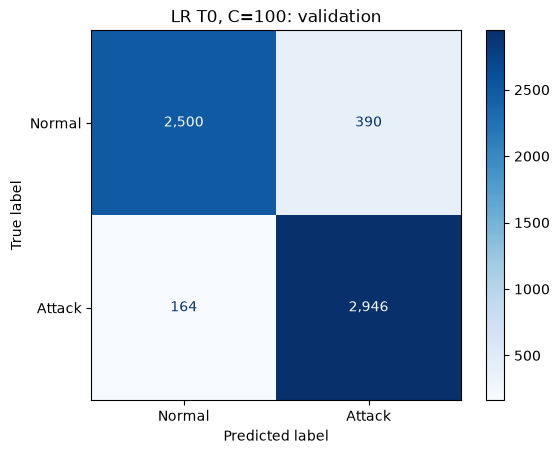

The selected T0 model makes **390 false alarms** among 2,890 normal flows (FPR 13.49%) and misses **164 attacks** among 3,110 attacks (5.27%). Correlated inputs, overlapping class distributions and omitted interactions are possible contributors; the confusion matrix alone cannot distinguish them.

In [9]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(
    y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",",
)
plt.title(f"LR T0, C={best['value']:g}: validation")
plt.savefig(FIGS / "confusion_lr_t0.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_val, pred_val, labels=[0, 1]).ravel()
display(Markdown(
    f"The selected T0 model makes **{fp:,} false alarms** among {tn + fp:,} normal "
    f"flows (FPR {fp / (tn + fp):.2%}) and misses **{fn:,} attacks** among "
    f"{tp + fn:,} attacks ({fn / (tp + fn):.2%}). "
    "Correlated inputs, overlapping class distributions and omitted interactions "
    "are possible contributors; the confusion matrix alone cannot distinguish them."
))

**Which attack types are missed?**

As in the reference notebook, inspect attack recall using `attack_cat` only as
metadata, never as a predictor. The EDA found feature-level overlap between
Fuzzers and Normal, so inspect Fuzzers explicitly rather than relying only on the
overall F1. Small validation groups such as Worms produce uncertain recall
estimates; catching every one of a few rows does not establish perfect detection.

In [10]:
by_attack = attack_recall(y_val, pred_val, cat_val)
display(by_attack)
most_missed = by_attack["missed"].idxmax()
display(Markdown(
    f"**{most_missed}** contributes the largest absolute number of missed attacks "
    f"({int(by_attack.loc[most_missed, 'missed'])}). Compare both the number missed "
    "and the recall: common attack types can dominate the total errors even when "
    "their recall is relatively high. These counts are recomputed when rerunning."
))
if "Fuzzers" in by_attack.index:
    display(Markdown(
        f"Fuzzers recall is {by_attack.loc['Fuzzers', 'recall']:.1%}, with "
        f"{int(by_attack.loc['Fuzzers', 'missed'])} misses out of "
        f"{int(by_attack.loc['Fuzzers', 'rows'])} validation examples. "
        "Difficulty on this group is consistent with the EDA's feature-overlap finding; "
        "it does not establish the cause of each error. T0's additive boundary cannot "
        "create the feature interactions that an expanded basis could supply."
    ))


,rows,caught,missed,recall
type,,,,
Fuzzers,899,770,129,0.857
Analysis,89,86,3,0.966
DoS,212,207,5,0.976
Exploits,1105,1085,20,0.982
Backdoor,85,84,1,0.988
Reconnaissance,419,414,5,0.988
Generic,233,232,1,0.996
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


**Fuzzers** contributes the largest absolute number of missed attacks (129). Compare both the number missed and the recall: common attack types can dominate the total errors even when their recall is relatively high. These counts are recomputed when rerunning.

Fuzzers recall is 85.7%, with 129 misses out of 899 validation examples. Difficulty on this group is consistent with the EDA's feature-overlap finding; it does not establish the cause of each error. T0's additive boundary cannot create the feature interactions that an expanded basis could supply.

**How the original preprocessed features enter the prediction**

T0 keeps named inputs, so inspect the largest absolute coefficients of the
selected model. Positive coefficients increase predicted attack log-odds; negative
coefficients decrease them, holding the other encoded inputs fixed. For scaled
numeric columns, one unit represents one training standard deviation after any
log transform. Category columns are 0/1 indicators and are not standardized, so
absolute coefficient size is not a universal importance measure across both types.
Full one-hot blocks and correlated features also make individual coefficients
reference-dependent; they are associations, not causal effects.

In [11]:
names = best_model.named_steps["columntransformer"].get_feature_names_out()
weights = best_model.named_steps["logisticregression"].coef_[0]
assert len(names) == len(weights) == 73
coefficient_table = pd.DataFrame({"feature": names, "coefficient": weights})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
display(coefficient_table.sort_values("absolute_coefficient", ascending=False).head(15).round(4))
ttl_names = {"num__sttl", "num__dttl", "log__ct_state_ttl"}
top_names = set(coefficient_table.nlargest(15, "absolute_coefficient")["feature"])
visible_ttl = sorted(ttl_names.intersection(top_names))
if visible_ttl:
    display(Markdown(
        "TTL-related columns among these large coefficients: " + ", ".join(visible_ttl) +
        ". This is consistent with the lab-shortcut concern in the EDA. A separate "
        "refit without TTL features is needed to measure their contribution to F1."
    ))


,feature,coefficient,absolute_coefficient
33,cat__state_RST,16.8424,16.8424
67,num__dttl,16.4728,16.4728
31,cat__state_CON,-12.4188,12.4188
29,cat__state_FIN,-9.9267,9.9267
69,num__dwin,-8.6012,8.6012
0,cat__proto_tcp,-8.1383,8.1383
32,cat__state_REQ,7.6908,7.6908
30,cat__state_INT,6.6072,6.6072
10,cat__proto_sun-nd,6.4504,6.4504
23,cat__service_pop3,6.4190,6.4190


TTL-related columns among these large coefficients: num__dttl. This is consistent with the lab-shortcut concern in the EDA. A separate refit without TTL features is needed to measure their contribution to F1.

**7. Save the results**

Save six rows to `results/lr_t0.csv` using the same columns and shared metrics as
T2, with `model="LR"`, `transformation="T0"` and `param="C"`. The comparison is
controlled: same splits, preprocessing, solver family, C grid, selection metric
and threshold; T0 retains 73 inputs while T2 uses its PCA representation. Do not
infer which is better before comparing the actual validation results.

The plots use T0-specific filenames, leaving T2 outputs intact. The official test
set remains reserved for the final selected configuration. Fitted pipelines stay
in memory in `fitted`; this notebook saves metrics, not a serialized model.

In [12]:
results.to_csv(RESULTS / "lr_t0.csv", index=False)
print("Saved", len(results), "rows to", RESULTS / "lr_t0.csv")
print("Plots:", FIGS / "curve_lr_t0.png", "and", FIGS / "confusion_lr_t0.png")

Saved 6 rows to /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/results/lr_t0.csv
Plots: /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/figures/curve_lr_t0.png and /Users/victoriajiang/Documents/GitHub/Network-Cyberattack-Detection/figures/confusion_lr_t0.png
